In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [2]:
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

In [3]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

In [4]:
transform = transforms.ToTensor()

In [5]:
train_data = datasets.MNIST(
    root="./Data", train=True, download=True, transform=transform
)
test_data = datasets.MNIST(
    root="./Data", train=False, download=True, transform=transform
)

In [6]:
train_data

Dataset MNIST
    Number of datapoints: 60000
    Root location: ./Data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [7]:
test_data

Dataset MNIST
    Number of datapoints: 10000
    Root location: ./Data
    Split: Test
    StandardTransform
Transform: ToTensor()

In [8]:
image, label = train_data[0]
image.shape

torch.Size([1, 28, 28])

In [9]:
label

5

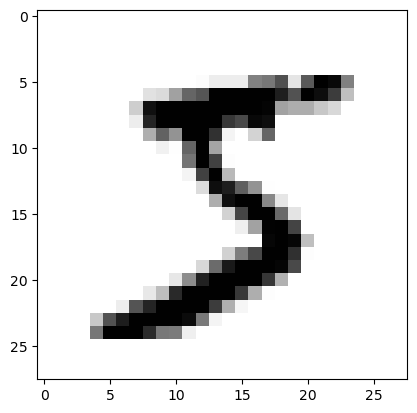

In [10]:
plt.imshow(image.reshape(28, 28), cmap="gist_yarg")
# viridis by default

In [11]:
torch.manual_seed(101)
train_loader = DataLoader(train_data, batch_size=100, shuffle=True)
test_loader = DataLoader(test_data, batch_size=500, shuffle=False)

In [12]:
type(train_loader)

torch.utils.data.dataloader.DataLoader

In [13]:
for images, labels in train_loader:
    break

print(images.shape, labels.shape)

torch.Size([100, 1, 28, 28]) torch.Size([100])


In [14]:
np.set_printoptions(formatter=dict(int=lambda x: f"{x:4}"))  # Formatting

label:  [   7    2    3    5    8    5    3    6    9    9    1    3]


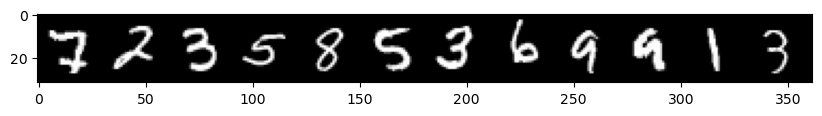

In [15]:
print("label: ", labels[:12].numpy())
im = make_grid(images[:12], nrow=12)
plt.figure(figsize=(10, 4))

plt.imshow(np.transpose(im.numpy(), (1, 2, 0)))

In [16]:
im.shape

torch.Size([3, 32, 362])

In [17]:
im[0, :, :].shape

torch.Size([32, 362])

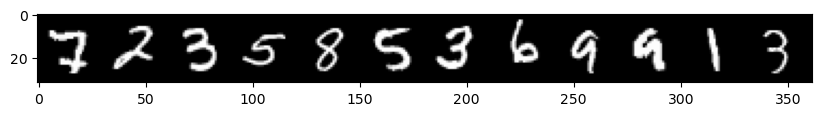

In [18]:
plt.figure(figsize=(10, 4))
plt.imshow(im[1, :, :], cmap="gray")

In [19]:
images[:10].shape

torch.Size([10, 1, 28, 28])

In [20]:
class MultilayerPerceptron(nn.Module):
    def __init__(self, in_sz=784, out_sz=10, layers=[120, 84]):
        super().__init__()
        self.fc1 = nn.Linear(in_sz, layers[0])
        self.fc2 = nn.Linear(layers[0], layers[1])
        self.fc3 = nn.Linear(layers[1], out_sz)

    def forward(self, X):
        # print(X.shape)
        X = F.relu(self.fc1(X))
        # print(X.shape)
        X = F.relu(self.fc2(X))
        # print(X.shape)
        X = self.fc3(X)
        # print(X.shape)

        # return F.log_softmax(X, dim=1)
        return X

In [21]:
model = MultilayerPerceptron()
model

MultilayerPerceptron(
  (fc1): Linear(in_features=784, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

In [22]:
total_params = 0
for param in model.parameters():
    total_params += param.numel()
    print(param.numel(), param.shape)

print("\n", total_params)

94080 torch.Size([120, 784])
120 torch.Size([120])
10080 torch.Size([84, 120])
84 torch.Size([84])
840 torch.Size([10, 84])
10 torch.Size([10])

 105214


In [ ]:
total_params = 0

for name, param in model.named_parameters():
    print(name, "\t", param.shape, f"number of params in layar {param.numel()}")
    total_params += param.numel()

print(f"\nThe total parameters in ANN: {total_params}")

fc1.weight 	 torch.Size([120, 784]) number of params in layar 94080
fc1.bias 	 torch.Size([120]) number of params in layar 120
fc2.weight 	 torch.Size([84, 120]) number of params in layar 10080
fc2.bias 	 torch.Size([84]) number of params in layar 84
fc3.weight 	 torch.Size([10, 84]) number of params in layar 840
fc3.bias 	 torch.Size([10]) number of params in layar 10

The total parameters in ANN: 105214


In [261]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [262]:
images.shape

torch.Size([100, 1, 28, 28])

In [ ]:
import time

start_time = time.time()

epochs = 5

for i in range(epochs):
    trn_corr = 0
    tst_corr = 0

    for b, (X_train, y_train) in enumerate(train_loader):
        b += 1
        y_pred = model(X_train.view(100, -1))

        loss = criterion(y_pred, y_train)

        predicted = torch.max(y_pred.data, 1)[1]

        # print('\ny_pred', type(y_pred), y_pred.shape, y_pred, sep='\n')
        # print('\ny_pred[0]', type(y_pred[0]), y_pred[0].shape, y_pred[0], sep='\n')

        # print('\ny_pred.data', type(y_pred.data), y_pred.data.shape, y_pred.data, sep='\n')
        # print('\ny_pred.data[0]', type(y_pred.data[0]), y_pred.data[0].shape, y_pred.data[0], sep='\n')

        optimizer.zero_grad()
        loss.backward()
        optimizer.step

        print(f"Batch: {b}")
        # break
        # print(y_pred.data)

    print(f"\n\n\nEpoch: {i + 1}\n\n\n")
    # break

Batch: 1
Batch: 2
Batch: 3
Batch: 4
Batch: 5
Batch: 6
Batch: 7
Batch: 8
Batch: 9
Batch: 10
Batch: 11


Batch: 12
Batch: 13
Batch: 14
Batch: 15
Batch: 16
Batch: 17
Batch: 18
Batch: 19
Batch: 20
Batch: 21
Batch: 22
Batch: 23
Batch: 24
Batch: 25
Batch: 26
Batch: 27
Batch: 28
Batch: 29
Batch: 30
Batch: 31
Batch: 32
Batch: 33
Batch: 34
Batch: 35
Batch: 36
Batch: 37
Batch: 38
Batch: 39
Batch: 40
Batch: 41
Batch: 42
Batch: 43
Batch: 44
Batch: 45
Batch: 46
Batch: 47
Batch: 48
Batch: 49
Batch: 50
Batch: 51
Batch: 52
Batch: 53
Batch: 54
Batch: 55
Batch: 56
Batch: 57
Batch: 58
Batch: 59
Batch: 60
Batch: 61
Batch: 62
Batch: 63
Batch: 64
Batch: 65
Batch: 66
Batch: 67
Batch: 68
Batch: 69
Batch: 70
Batch: 71
Batch: 72
Batch: 73
Batch: 74
Batch: 75
Batch: 76
Batch: 77
Batch: 78
Batch: 79
Batch: 80
Batch: 81
Batch: 82
Batch: 83
Batch: 84
Batch: 85
Batch: 86
Batch: 87
Batch: 88
Batch: 89
Batch: 90
Batch: 91
Batch: 92
Batch: 93
Batch: 94
Batch: 95
Batch: 96
Batch: 97
Batch: 98
Batch: 99
Batch: 100
Batch: 101
Batch: 102
Batch: 103
Batch: 104
Batch: 105
Batch: 106
Batch: 107
Batch: 108
Batch: 109
Batch: 110

KeyboardInterrupt: 

In [ ]:
# y_pred[1].data

In [ ]:
# y_pred.data[1]

In [ ]:
# print(torch.max(y_pred,1)[0])
# print(torch.max(y_pred.data,1)[0])

In [ ]:
# print(type(torch.max(y_pred,1)[0]))
# print(type(torch.max(y_pred.data,1)[0]))

In [ ]:
# print(torch.max(y_pred,1)[1])
# print(torch.max(y_pred.data,1)[1])

In [ ]:
# print(type(torch.max(y_pred,1)[1]))
# print(type(torch.max(y_pred.data,1)[1]))